# Single-RF tutorial: four-fold image-held-out evaluation, with and without GMM voting
Preprocessing and pre-RF GMM are illustrated on the same image as the implementation tutorial. Eight other images with archived manual labels **11 and 22** form the binary supervised dataset. No class merging, pseudo-labels or hierarchical RF is used.

In **four folds**, six images fit one RF and the other two images are evaluated. Every image is held out exactly once. Each fold's SAME RF is scored in two modes: independent superpixel predictions (**RF only**), or predictions majority-voted within the image's pre-RF GMM groups (**RF + GMM vote**). Training labels, confidence filtering, split and RF parameters are identical between modes. Ties in voting choose the smaller label, matching the shared implementation.

GMM is still required to reconstruct the archived manual annotations in both modes. Therefore “without GMM” means **without GMM voting at prediction time**, not independent non-GMM ground truth. Because annotations themselves label entire GMM groups, voting may improve agreement partly by enforcing that same group structure. These scores are not independent pixel-level accuracy or external validation.

A separate final RF is fitted on all eight images in Cell 7. It is never used for scores: Cell 8 creates four NEW six-image RFs for cross-validation. Use **Python (crystal_seg)** from `training/` or the project root. Drawing code is inline; shared numerical functions come from `implement/`. Images are not resized. Main analysis models and outputs are unchanged.

## 1. Paths and configuration

In [1]:
from pathlib import Path
import sys, json, ast, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

WORK_DIR = Path.cwd().resolve()
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): WORK_DIR /= "training"
if not (WORK_DIR / "training_tutorial.ipynb").is_file(): raise FileNotFoundError("Start from training/ or the project root.")
PROJECT_ROOT = WORK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "implement"))
from crystal_pipeline import _natural_key
from crystal_preprocessing import preprocess_image
from crystal_features import calculate_image_features, FEATURE_NAMES, FEATURE_CALCULATION
from crystal_gmm import fit_image_gmm

# Match the implementation tutorial's current illustrative image.
IMAGE_PATH = PROJECT_ROOT / "data/mag500/old/pl09/20260806_140719.jpg"
TRAINING_DIR = PROJECT_ROOT / "data/mag500/training"
ARCHIVE_PATH = WORK_DIR / "archive/superpixel_RF_GMM_training.ipynb"
REFERENCE_PATH = WORK_DIR / "data/models/color_reference.pkl"
OUTPUT_DIR = WORK_DIR / "output/tutorial_single_rf_001"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONFIG = {"crop": {"top": 60, "bottom": 100, "left": 60, "right": 100}, "n_segments": 300, "compactness": 10.0}
CLASS_IDS = [11, 22]
GMM_PROBABILITY_CUT = .70
reference = np.asarray(joblib.load(REFERENCE_PATH)["reference_mean"], dtype=np.float64)
print(f"Example image: {IMAGE_PATH}\nTraining folder: {TRAINING_DIR}\nOutputs: {OUTPUT_DIR}")
from sklearn.ensemble import RandomForestClassifier
RF_PARAMS = dict(n_estimators=200, min_samples_leaf=2, class_weight="balanced", random_state=0, n_jobs=1)
CV_DIR = OUTPUT_DIR / "cross_validation"


Example image: /home/kmanabe2403/dune/data/mag500/old/pl09/20260806_140719.jpg
Training folder: /home/kmanabe2403/dune/data/mag500/training
Outputs: /home/kmanabe2403/dune/training/output/tutorial_single_rf_001


## 2. Crop the example image
Black frames show the image edges; the red rectangle marks the retained region. No resizing is applied.

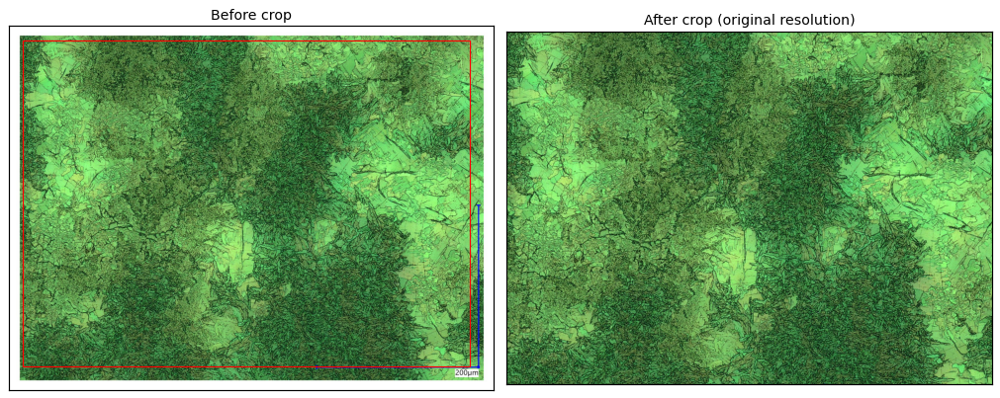

In [2]:
from skimage import io
from matplotlib.patches import Rectangle

original = io.imread(IMAGE_PATH)
h, w = original.shape[:2]
crop = CONFIG["crop"]
image = original[crop["top"]:h-crop["bottom"], crop["left"]:w-crop["right"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(original)
axes[0].add_patch(Rectangle((crop["left"]-.5, crop["top"]-.5), image.shape[1], image.shape[0], fill=False, edgecolor="red", linewidth=1))
axes[0].set_title("Before crop")
axes[1].imshow(image)
axes[1].set_title("After crop (original resolution)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values(): spine.set(color="black", linewidth=1)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_crop.png", dpi=120)
plt.show()
plt.close(fig)
del original

## 3. Superpixels and the same 18 archived-training features
The helper processes one image and saves intermediate arrays before returning. Fixed-reference Lab correction and the feature calculation match the current implementation modules (`archived_training_v1`). Thin red lines show SLIC boundaries. Do not resize images or change the preprocessing/reference when reusing archived cluster IDs.

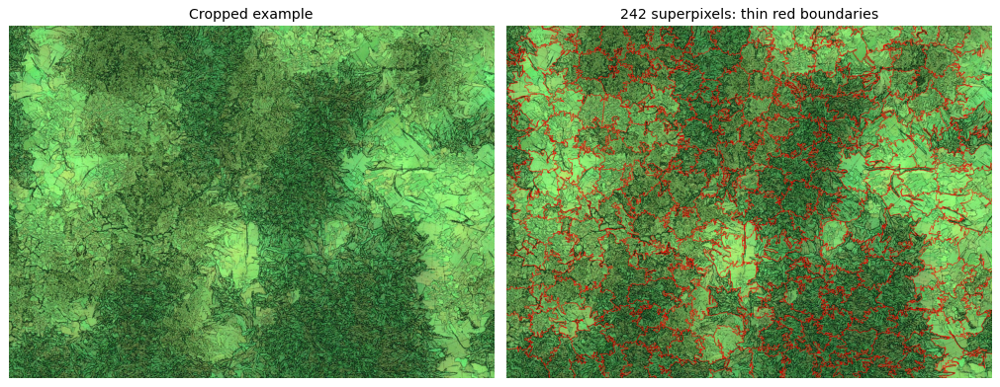

In [3]:
def prepare_image(path, directory):
    preprocess_image(path, directory, CONFIG)
    with np.load(directory / "lab_means.npz") as saved:
        labels, means = saved["labels"], saved["lab_means"]
    correction = reference - means.mean(axis=0)
    corrected = directory / "corrected_lab.npz"
    np.savez(corrected, labels=labels, lab_means=means + correction, correction=correction)
    labels, features = calculate_image_features(directory, corrected)
    feature_path = directory / "features.npz"
    np.savez(feature_path, labels=labels, features=features, feature_names=FEATURE_NAMES, feature_calculation=FEATURE_CALCULATION)
    return feature_path

from skimage.segmentation import mark_boundaries
EXAMPLE_DIR = OUTPUT_DIR / "example"
example_features = prepare_image(IMAGE_PATH, EXAMPLE_DIR)
segments = np.load(EXAMPLE_DIR / "segments.npy")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title("Cropped example")
axes[1].imshow(np.clip(mark_boundaries(image, segments, color=(1, 0, 0), mode="inner"), 0, 1))
axes[1].set_title(f"{len(np.unique(segments))} superpixels: thin red boundaries")
for ax in axes: ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_superpixels.png", dpi=120)
plt.show()
plt.close(fig)

## 4. Pre-RF GMM: original image, area fractions and separated clusters
The layout matches the implementation tutorial: original image and pixel-area fractions on top; original-color superpixels from each GMM component on white backgrounds below. No EM-iteration or PCA-distribution plot is displayed. GMM still uses two PCs internally to match archived training. These unsupervised component IDs are not RF labels 11/22. The example image is separate from the supervised dataset.

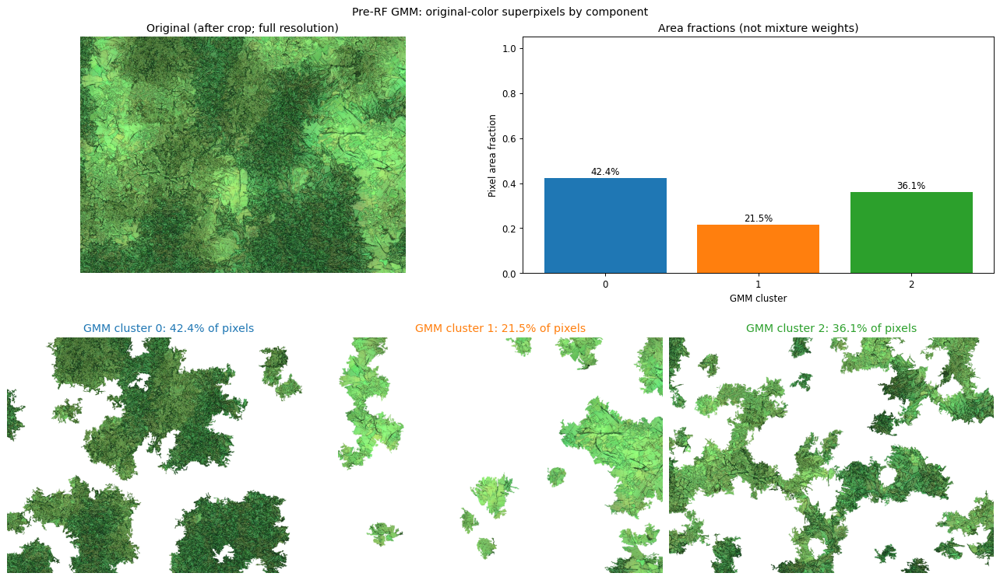

In [4]:
example_gmm = fit_image_gmm(example_features, n_components=3, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
with np.load(example_features) as saved: example_labels = saved["labels"]
cluster_labels = np.full(len(example_labels), -1, dtype=int)
cluster_labels[example_gmm["valid_indices"]] = example_gmm["cluster_labels"]
cluster_map = cluster_labels[np.searchsorted(example_labels, segments)]
colors = plt.cm.tab10(np.arange(3))
area = np.bincount(cluster_map.ravel(), minlength=3) / cluster_map.size
fig = plt.figure(figsize=(15, 9), layout="constrained")
top, bottom = fig.subfigures(2, 1)
original_ax, area_ax = top.subplots(1, 2)
original_ax.imshow(image)
original_ax.set_title("Original (after crop; full resolution)")
original_ax.axis("off")
area_ax.bar(np.arange(3), area, color=colors)
area_ax.set(xlabel="GMM cluster", ylabel="Pixel area fraction", xticks=np.arange(3), ylim=(0, 1.05), title="Area fractions (not mixture weights)")
for k, value in enumerate(area): area_ax.text(k, value + .015, f"{value:.1%}", ha="center")
for k, ax in enumerate(np.atleast_1d(bottom.subplots(1, 3))):
    view = np.full_like(image, 255)
    mask = cluster_map == k
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(f"GMM cluster {k}: {area[k]:.1%} of pixels", color=colors[k])
    ax.axis("off")
fig.suptitle("Pre-RF GMM: original-color superpixels by component")
fig.savefig(OUTPUT_DIR / "03_example_gmm.png", dpi=120)
plt.show()
plt.close(fig)
np.savez_compressed(EXAMPLE_DIR / "gmm.npz", **example_gmm)
del image, segments, view

## 5. Select eight images with exactly two archived manual labels
Extract literal arrays from the archived notebook using AST; no archived code is executed. The saved filename order and GMM counts are checked against the current training folder before importing labels. The fixed eight-image selection contains only **11 and 22**, and uses first-stage GMM annotations with no nested splits. Images are chosen from existing annotations, not by RF scores. Content hashes prevent duplicate files entering opposite partitions.

In [5]:
archive = json.loads(ARCHIVE_PATH.read_text())
def archive_literal(cell_index, variable):
    source = archive["cells"][cell_index]["source"]
    tree = ast.parse("".join(source) if isinstance(source, list) else source)
    for node in tree.body:
        if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == variable for t in node.targets):
            return ast.literal_eval(node.value)
    raise KeyError(variable)

archive_counts = archive_literal(9, "gmm_n_components")
archive_labels = archive_literal(12, "manual_cluster_labels")
settings = pd.read_csv(WORK_DIR / "data/tables/gmm_settings.csv")
all_paths = sorted(TRAINING_DIR.glob("*.jpg"), key=_natural_key)
assert [p.stem for p in all_paths] == settings["name"].tolist(), "Training image order changed; recheck archive correspondence."
assert len(archive_labels) == len(settings) == len(archive_counts)
assert archive_counts == settings.n_components.tolist()
ARCHIVE_INDICES = [12, 14, 27, 28, 29, 31, 32, 33]  # Zero-based original image indices.
records = []
for image_id, index in enumerate(ARCHIVE_INDICES):
    path, labels = all_paths[index], archive_labels[index]
    if len(labels) != archive_counts[index] or any(not isinstance(v, int) or v not in CLASS_IDS for v in labels):
        raise ValueError("Selected archive labels must be flat and contain only 11 or 22.")
    records.append({"image_id": image_id, "archive_index": index, "name": path.stem,
                    "path": str(path.relative_to(PROJECT_ROOT)), "image_hash": hashlib.sha256(path.read_bytes()).hexdigest(),
                    "n_components": archive_counts[index], "archive_labels": json.dumps(labels)})
manifest = pd.DataFrame(records)
assert manifest.image_hash.nunique() == 8
assert hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest() not in set(manifest.image_hash)
manifest.to_csv(OUTPUT_DIR / "images.csv", index=False)
provenance = {"archive": str(ARCHIVE_PATH.relative_to(PROJECT_ROOT)), "archive_sha256": hashlib.sha256(ARCHIVE_PATH.read_bytes()).hexdigest(),
              "counts_cell_index": 9, "labels_cell_index": 12, "class_ids": CLASS_IDS, "preprocessing": CONFIG,
              "reference_mean": reference.tolist(), "feature_calculation": FEATURE_CALCULATION}
(OUTPUT_DIR / "label_provenance.json").write_text(json.dumps(provenance, indent=2) + "\n")
display(manifest[["image_id", "archive_index", "name", "n_components", "archive_labels"]])

,image_id,archive_index,name,n_components,archive_labels
0,0,12,0074_20260807_124023,3,"[22, 11, 11]"
1,1,14,0078_20260807_124259,3,"[11, 22, 11]"
2,2,27,0152_20260806_131657,2,"[11, 22]"
3,3,28,0153_20260806_131743,2,"[11, 11]"
4,4,29,0154_20260806_131837,2,"[22, 22]"
5,5,31,0157_20260806_132046,2,"[22, 22]"
6,6,32,0158_20260806_132119,2,"[22, 11]"
7,7,33,0159_20260806_132151,2,"[11, 22]"


## 6. Reconstruct GMM annotations and build the supervised dataset
Process the eight images at original resolution with their archived first-stage component counts (2 or 3), then seed `cluster_labels.csv` from the archived manual labels. Existing manual edits are preserved. A first-image cluster preview allows inspection of the correspondence.

Expand each group's annotation to its superpixels. Eligible rows have a nonblank label and GMM probability ≥ 0.70. `superpixel_index` indexes a feature row; `segment_label` is the actual SLIC ID. Preserve all valid rows in `superpixels.csv` and save eligible rows to `rf_training.csv`. Use a new output directory if images, reference, features or GMM settings change.

1/8: 0074_20260807_124023; 260 superpixels; labels [22, 11, 11]
2/8: 0078_20260807_124259; 258 superpixels; labels [11, 22, 11]
3/8: 0152_20260806_131657; 177 superpixels; labels [11, 22]
4/8: 0153_20260806_131743; 197 superpixels; labels [11, 11]
5/8: 0154_20260806_131837; 190 superpixels; labels [22, 22]
6/8: 0157_20260806_132046; 176 superpixels; labels [22, 22]
7/8: 0158_20260806_132119; 158 superpixels; labels [22, 11]
8/8: 0159_20260806_132151; 183 superpixels; labels [11, 22]
Eligible superpixels: 1,397 / 1,599; eight images, exactly two manual classes.


,image_id,name,gmm_cluster,manual_label,n_superpixels,archive_index
0,0,0074_20260807_124023,0,22,101,12
1,0,0074_20260807_124023,1,11,85,12
2,0,0074_20260807_124023,2,11,74,12
3,1,0078_20260807_124259,0,11,77,14
4,1,0078_20260807_124259,1,22,37,14
5,1,0078_20260807_124259,2,11,144,14
6,2,0152_20260806_131657,0,11,94,27
7,2,0152_20260806_131657,1,22,83,27
8,3,0153_20260806_131743,0,11,123,28
9,3,0153_20260806_131743,1,11,74,28


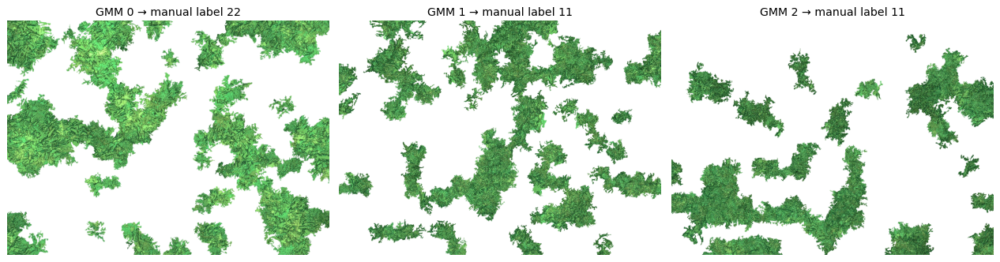

manual_label,11,22
name,,
0074_20260807_124023,128,90
0078_20260807_124259,173,35
0152_20260806_131657,88,75
0153_20260806_131743,186,0
0154_20260806_131837,0,158
0157_20260806_132046,0,165
0158_20260806_132119,94,41
0159_20260806_132151,50,114


In [6]:
cluster_rows = []
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    feature_path = prepare_image(PROJECT_ROOT / row.path, directory)
    result = fit_image_gmm(feature_path, row.n_components, pca_components=2, probability_cut=GMM_PROBABILITY_CUT)
    np.savez_compressed(directory / "gmm.npz", **result)
    for cluster, manual in enumerate(json.loads(row.archive_labels)):
        cluster_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": cluster, "manual_label": manual,
                             "n_superpixels": int(np.count_nonzero(result["cluster_labels"] == cluster)), "archive_index": row.archive_index})
    print(f"{row.image_id+1}/8: {row.name}; {len(result['valid_indices'])} superpixels; labels {row.archive_labels}", flush=True)
    gc.collect()
LABEL_PATH = OUTPUT_DIR / "cluster_labels.csv"
if not LABEL_PATH.exists(): pd.DataFrame(cluster_rows).to_csv(LABEL_PATH, index=False)
display(pd.read_csv(LABEL_PATH))
first = manifest.iloc[0]
directory = OUTPUT_DIR / "rf_data" / f"image_{first.image_id:04d}"
training_image, training_segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
with np.load(directory / "features.npz") as saved: labels = saved["labels"]
with np.load(directory / "gmm.npz") as saved:
    groups = np.full(len(labels), -1, dtype=int)
    groups[saved["valid_indices"]] = saved["cluster_labels"]
fig, axes = plt.subplots(1, int(first.n_components), figsize=(5 * int(first.n_components), 4), squeeze=False)
for cluster, ax in enumerate(axes.flat):
    view = np.full_like(training_image, 255)
    mask = groups[np.searchsorted(labels, training_segments)] == cluster
    view[mask] = training_image[mask]
    manual = pd.read_csv(LABEL_PATH).query("image_id == @first.image_id and gmm_cluster == @cluster").manual_label.iloc[0]
    ax.imshow(view)
    ax.set_title(f"GMM {cluster} → manual label {manual}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_archived_labels.png", dpi=120)
plt.show()
plt.close(fig)
del training_image, training_segments, view

# Expand manual group labels and select eligible supervised rows.
manual = pd.read_csv(LABEL_PATH)
if manual.duplicated(["image_id", "gmm_cluster"]).any(): raise ValueError("Duplicate manual cluster rows.")
rows = []
for row in manifest.itertuples(index=False):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    with np.load(directory / "features.npz") as saved: features, labels = saved["features"], saved["labels"]
    with np.load(directory / "gmm.npz") as saved:
        indices, clusters, probability = saved["valid_indices"], saved["cluster_labels"], saved["max_probability"]
    annotations = manual[manual.image_id == row.image_id]
    if set(annotations.gmm_cluster) != set(range(row.n_components)) or set(annotations.name) != {row.name}:
        raise ValueError("Manual annotations do not match the selected image/GMM.")
    lookup = pd.to_numeric(annotations.set_index("gmm_cluster").manual_label, errors="raise")
    if not set(lookup.dropna()).issubset(CLASS_IDS): raise ValueError("Use only manual labels 11 and 22, or blanks.")
    frame = pd.DataFrame(features[indices], columns=FEATURE_NAMES)
    frame["image_id"], frame["name"], frame["image_hash"] = row.image_id, row.name, row.image_hash
    frame["superpixel_index"], frame["segment_label"] = indices, labels[indices]
    frame["gmm_cluster"], frame["gmm_probability"] = clusters, probability
    frame["manual_label"] = lookup.reindex(clusters).to_numpy()
    rows.append(frame)
all_superpixels = pd.concat(rows, ignore_index=True)
all_superpixels.to_csv(OUTPUT_DIR / "superpixels.csv", index=False)
dataset = all_superpixels[all_superpixels.manual_label.notna() & (all_superpixels.gmm_probability >= GMM_PROBABILITY_CUT)].copy()
dataset["manual_label"] = dataset.manual_label.astype(int)
assert dataset.image_id.nunique() == 8 and set(dataset.manual_label) == set(CLASS_IDS)
dataset.to_csv(OUTPUT_DIR / "rf_training.csv", index=False)
display(dataset.groupby(["name", "manual_label"]).size().unstack(fill_value=0))
print(f"Eligible superpixels: {len(dataset):,} / {len(all_superpixels):,}; eight images, exactly two manual classes.")

## 7. Fit the final binary RF using all eight images
Fit the final demonstration model and save `rf_demo_all8.pkl`. **This model is not used for evaluation.** The following cell creates four separate RFs, each using only six images. Creating the all-eight model earlier does not feed its predictions or parameters into the evaluation models; only the fixed RF configuration is shared. The model supports labels 11/22 only, not the main implementation hierarchy.

In [7]:
final_rf = RandomForestClassifier(**RF_PARAMS).fit(dataset[FEATURE_NAMES], dataset.manual_label)
model_path = OUTPUT_DIR / "rf_demo_all8.pkl"
joblib.dump({"model": final_rf, "feature_names": FEATURE_NAMES, "feature_calculation": FEATURE_CALCULATION,
             "reference_mean": reference, "class_ids": CLASS_IDS, "preprocessing": CONFIG,
             "training_image_hashes": manifest.image_hash.tolist(), "label_provenance": provenance,
             "purpose": "binary RF refitted on all eight images; not used for cross-validation scores"}, model_path)
print(f"Final eight-image model: {model_path}\nCross-validation outputs (created by the following cells): {CV_DIR}")
print("Edit cluster_labels.csv and rerun cells 6–9 to update labels; choose a new run directory if inputs or GMM settings change.")

Final eight-image model: /home/kmanabe2403/dune/training/output/tutorial_single_rf_001/rf_demo_all8.pkl
Cross-validation outputs (created by the following cells): /home/kmanabe2403/dune/training/output/tutorial_single_rf_001/cross_validation
Edit cluster_labels.csv and rerun cells 6–9 to update labels; choose a new run directory if inputs or GMM settings change.


## 8. Four image folds × two prediction modes
Split the eight distinct image contents into four fixed pairs. Each pair is held out once, with the other six images used for fitting. The split is fixed before scoring and not optimized by test performance. All eligible annotated superpixels from an image stay together.

For each held-out image, predict all its superpixels using the fold's RF. RF only keeps those predictions. RF + GMM vote replaces each GMM group's predictions with the majority RF label among all valid superpixels in that group, including low-GMM-confidence rows, matching implementation voting. Both modes are scored on exactly the same eligible rows (nonblank manual labels, GMM probability ≥ 0.70).

In [8]:
from sklearn.model_selection import KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report
from crystal_rf import majority_vote

CV_DIR = OUTPUT_DIR / "cross_validation"
CV_DIR.mkdir(parents=True, exist_ok=True)
MODES = {"RF only": "rf_prediction", "RF + GMM vote": "rf_gmm_prediction"}
split_rows, prediction_frames, fold_rows, fold_importances = [], [], [], []
for fold, (train_position, test_position) in enumerate(KFold(n_splits=4, shuffle=True, random_state=42).split(manifest), 1):
    train_ids, test_ids = manifest.iloc[train_position].image_id, manifest.iloc[test_position].image_id
    train, test = dataset[dataset.image_id.isin(train_ids)], dataset[dataset.image_id.isin(test_ids)]
    assert train.image_id.nunique() == 6 and test.image_id.nunique() == 2
    assert set(train.image_hash).isdisjoint(test.image_hash)
    assert set(train.manual_label) == set(test.manual_label) == set(CLASS_IDS)
    model = RandomForestClassifier(**RF_PARAMS).fit(train[FEATURE_NAMES], train.manual_label)
    fold_importances.append(model.feature_importances_)
    fold_dir = CV_DIR / f"fold_{fold:02d}"
    fold_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": model, "feature_names": FEATURE_NAMES, "class_ids": CLASS_IDS, "reference_mean": reference,
                 "training_image_hashes": sorted(set(train.image_hash)), "test_image_hashes": sorted(set(test.image_hash)),
                 "fold": fold, "purpose": "six-image fit, same model for both inference modes"}, fold_dir / "evaluation_rf.pkl")
    for row in manifest.itertuples(index=False):
        split_rows.append({"fold": fold, "image_id": row.image_id, "name": row.name, "image_hash": row.image_hash,
                           "partition": "test" if row.image_id in set(test_ids) else "train"})
    image_frames = []
    for image_id in test_ids:
        directory = OUTPUT_DIR / "rf_data" / f"image_{image_id:04d}"
        with np.load(directory / "features.npz") as saved: features, labels = saved["features"], saved["labels"]
        with np.load(directory / "gmm.npz") as saved: indices, clusters = saved["valid_indices"], saved["cluster_labels"]
        direct = model.predict(pd.DataFrame(features, columns=FEATURE_NAMES))
        voted = direct.copy()
        for cluster in np.unique(clusters):
            members = indices[clusters == cluster]
            voted[members] = int(majority_vote(direct[members])[0])
        np.savez_compressed(fold_dir / f"image_{image_id:04d}_predictions.npz", labels=labels, rf_prediction=direct, rf_gmm_prediction=voted)
        scored = test[test.image_id == image_id][["image_id", "name", "superpixel_index", "segment_label", "manual_label", "gmm_probability"]].copy()
        scored["fold"] = fold
        scored["rf_prediction"], scored["rf_gmm_prediction"] = direct[scored.superpixel_index], voted[scored.superpixel_index]
        image_frames.append(scored)
    held_out = pd.concat(image_frames, ignore_index=True)
    prediction_frames.append(held_out)
    for mode, column in MODES.items():
        fold_rows.append({"fold": fold, "mode": mode, "accuracy": accuracy_score(held_out.manual_label, held_out[column]),
                          "balanced_accuracy": balanced_accuracy_score(held_out.manual_label, held_out[column]),
                          "macro_f1": f1_score(held_out.manual_label, held_out[column], labels=CLASS_IDS, average="macro"),
                          "n_train_images": 6, "n_test_images": 2, "n_train_superpixels": len(train), "n_test_superpixels": len(test)})
    print(f"Fold {fold}: train {list(train_ids)}, test {list(test_ids)}; both prediction modes evaluated.")
cv_predictions = pd.concat(prediction_frames, ignore_index=True)
cv_splits, fold_metrics = pd.DataFrame(split_rows), pd.DataFrame(fold_rows)
assert not cv_predictions.duplicated(["image_id", "superpixel_index"]).any()
assert cv_splits.query("partition == 'test'").groupby("image_id").size().eq(1).all()
assert len(cv_predictions) == len(dataset)
summary_rows, image_rows = [], []
for mode, column in MODES.items():
    fold_scores = fold_metrics[fold_metrics["mode"] == mode]
    summary_rows.append({"mode": mode, "pooled_accuracy": accuracy_score(cv_predictions.manual_label, cv_predictions[column]),
                         "pooled_balanced_accuracy": balanced_accuracy_score(cv_predictions.manual_label, cv_predictions[column]),
                         "pooled_macro_f1": f1_score(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS, average="macro"),
                         "mean_fold_accuracy": fold_scores.accuracy.mean(), "std_fold_accuracy": fold_scores.accuracy.std(),
                         "n_test_images": 8, "n_test_superpixels": len(cv_predictions)})
    for image_id, scored in cv_predictions.groupby("image_id"):
        image_rows.append({"image_id": image_id, "name": scored.name.iloc[0], "fold": scored.fold.iloc[0], "mode": mode,
                           "accuracy": accuracy_score(scored.manual_label, scored[column]), "n_superpixels": len(scored)})
cv_summary, image_metrics = pd.DataFrame(summary_rows), pd.DataFrame(image_rows)
for name, table in {"splits": cv_splits, "predictions": cv_predictions, "fold_metrics": fold_metrics,
                    "summary_metrics": cv_summary, "image_metrics": image_metrics}.items(): table.to_csv(CV_DIR / f"{name}.csv", index=False)
display(cv_splits.query("partition == 'test'")[["fold", "image_id", "name"]])
display(fold_metrics)
display(cv_summary)

Fold 1: train [0, 2, 3, 4, 6, 7], test [1, 5]; both prediction modes evaluated.
Fold 2: train [1, 2, 3, 4, 5, 6], test [0, 7]; both prediction modes evaluated.
Fold 3: train [0, 1, 3, 5, 6, 7], test [2, 4]; both prediction modes evaluated.
Fold 4: train [0, 1, 2, 4, 5, 7], test [3, 6]; both prediction modes evaluated.


,fold,image_id,name
1,1,1,0078_20260807_124259
5,1,5,0157_20260806_132046
8,2,0,0074_20260807_124023
15,2,7,0159_20260806_132151
18,3,2,0152_20260806_131657
20,3,4,0154_20260806_131837
27,4,3,0153_20260806_131743
30,4,6,0158_20260806_132119


,fold,mode,accuracy,balanced_accuracy,macro_f1,n_train_images,n_test_images,n_train_superpixels,n_test_superpixels
0,1,RF only,0.911528,0.912428,0.911273,6,2,1024,373
1,1,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1024,373
2,2,RF only,0.769634,0.775364,0.769406,6,2,1015,382
3,2,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1015,382
4,3,RF only,0.900312,0.927795,0.885633,6,2,1076,321
5,3,RF + GMM vote,1.000000,1.000000,1.000000,6,2,1076,321
6,4,RF only,0.638629,0.792857,0.576440,6,2,1076,321
7,4,RF + GMM vote,0.707165,0.832143,0.632096,6,2,1076,321


,mode,pooled_accuracy,pooled_balanced_accuracy,pooled_macro_f1,mean_fold_accuracy,std_fold_accuracy,n_test_images,n_test_superpixels
0,RF only,0.807445,0.808141,0.807445,0.805026,0.128274,8,1397
1,RF + GMM vote,0.932713,0.934631,0.932616,0.926791,0.146417,8,1397


## 9. Cross-validation scores and image comparisons
Blue confusion matrices show pooled out-of-fold counts. Accuracy and balanced accuracy compare the four held-out pairs; feature importance averages the four six-image RFs. Pooled scores weight eligible superpixels equally, whereas mean fold accuracy weights folds equally.

Save all eight original/prediction/reference/correctness comparison PNGs, displaying images 0, 1 and the requested low-accuracy image 6 here. Green means correct, red incorrect, and gray **unscored**: the corresponding superpixel has no eligible reference label, usually because its GMM probability is below 0.70. Gray is not another crystal class. Predictions are made for all superpixels, but scores use the same eligible subset in both modes. GMM voting includes all valid superpixels, even those not scored.

The final audit table lists each GMM group's archived label, raw RF votes and scored correct counts for image 6. An incorrect majority can overwrite correct minority predictions. Because reference labels were assigned by GMM groups, increased voting agreement is not independent proof of pixel-level correctness.

Finally, compare all nine original-color GMM groups annotated as label 11 in a 3 × 3 grid. The low-accuracy image 6, GMM group 1 is first and outlined in red. All group superpixels are shown, including unscored ones; white regions are excluded from that group, not a predicted background class.

The same comparison follows for all nine groups annotated as label 22. Image 6, GMM group 0 is first and outlined in red; colors, masking and confidence inclusion match the label-11 figure.

Requested case: image 6, 0158_20260806_132119; counts use the same out-of-fold RF.


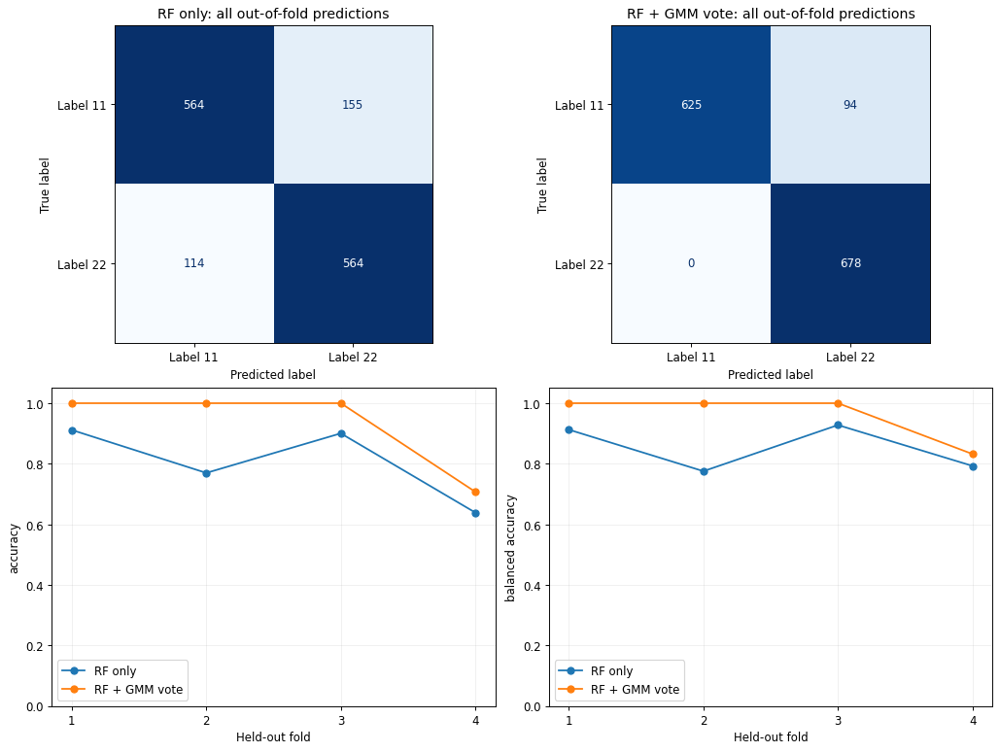

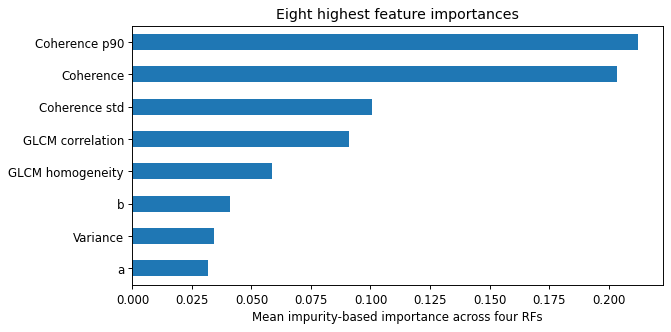

,mode,pooled_accuracy,pooled_balanced_accuracy,pooled_macro_f1,mean_fold_accuracy,std_fold_accuracy,n_test_images,n_test_superpixels
0,RF only,0.807445,0.808141,0.807445,0.805026,0.128274,8,1397
1,RF + GMM vote,0.932713,0.934631,0.932616,0.926791,0.146417,8,1397


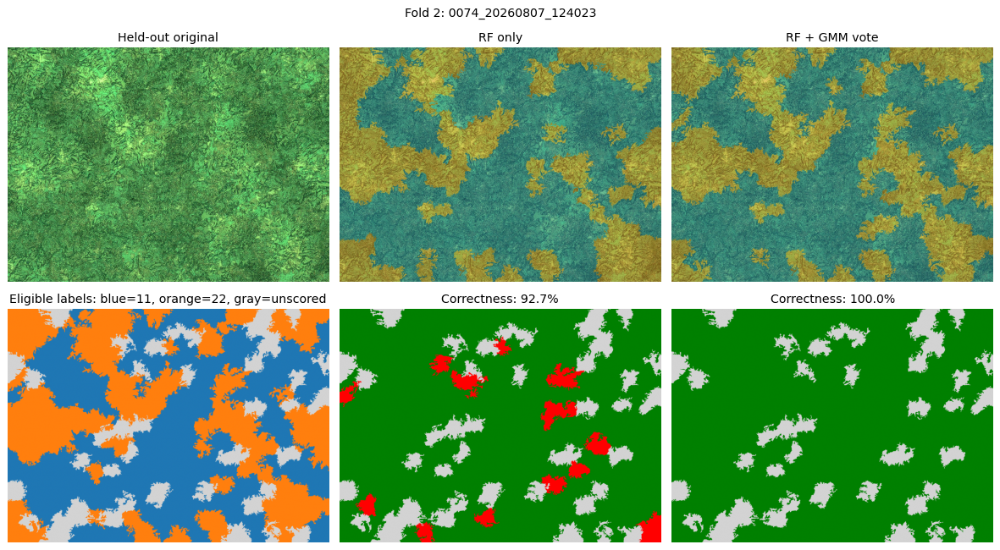

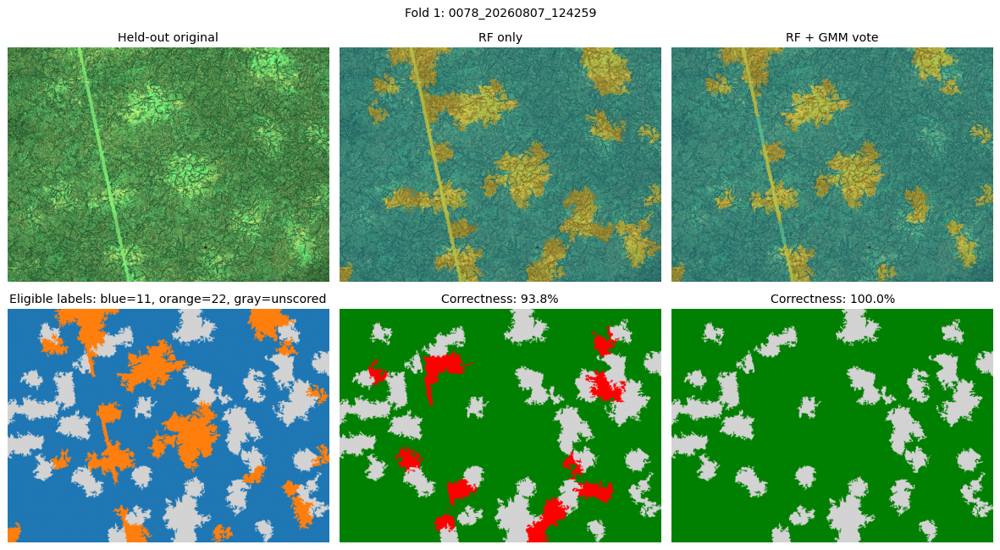

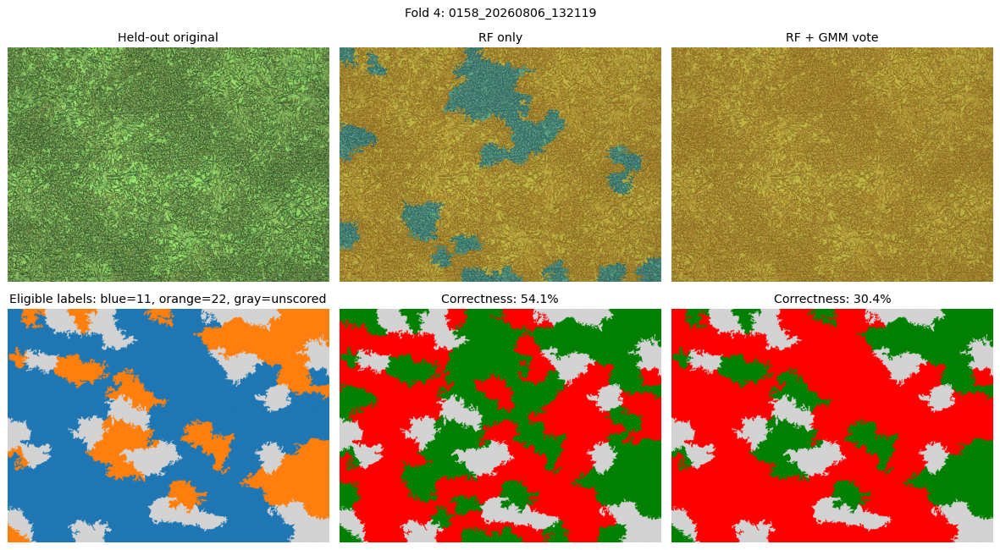

,image_id,name,fold,mode,accuracy,n_superpixels
0,0,0074_20260807_124023,2,RF only,0.926606,218
1,1,0078_20260807_124259,1,RF only,0.937500,208
2,2,0152_20260806_131657,3,RF only,0.834356,163
3,3,0153_20260806_131743,4,RF only,0.709677,186
4,4,0154_20260806_131837,3,RF only,0.968354,158
5,5,0157_20260806_132046,1,RF only,0.878788,165
6,6,0158_20260806_132119,4,RF only,0.540741,135
7,7,0159_20260806_132151,2,RF only,0.560976,164
8,0,0074_20260807_124023,2,RF + GMM vote,1.000000,218
9,1,0078_20260807_124259,1,RF + GMM vote,1.000000,208


,image_id,name,fold,gmm_cluster,manual_label,n_total,n_scored,n_unscored,votes_11_all,votes_22_all,majority_label,correct_rf_scored,correct_vote_scored
14,6,0158_20260806_132119,4,0,22,49,41,8,1,48,22,41,41
15,6,0158_20260806_132119,4,1,11,109,94,15,32,77,22,32,0


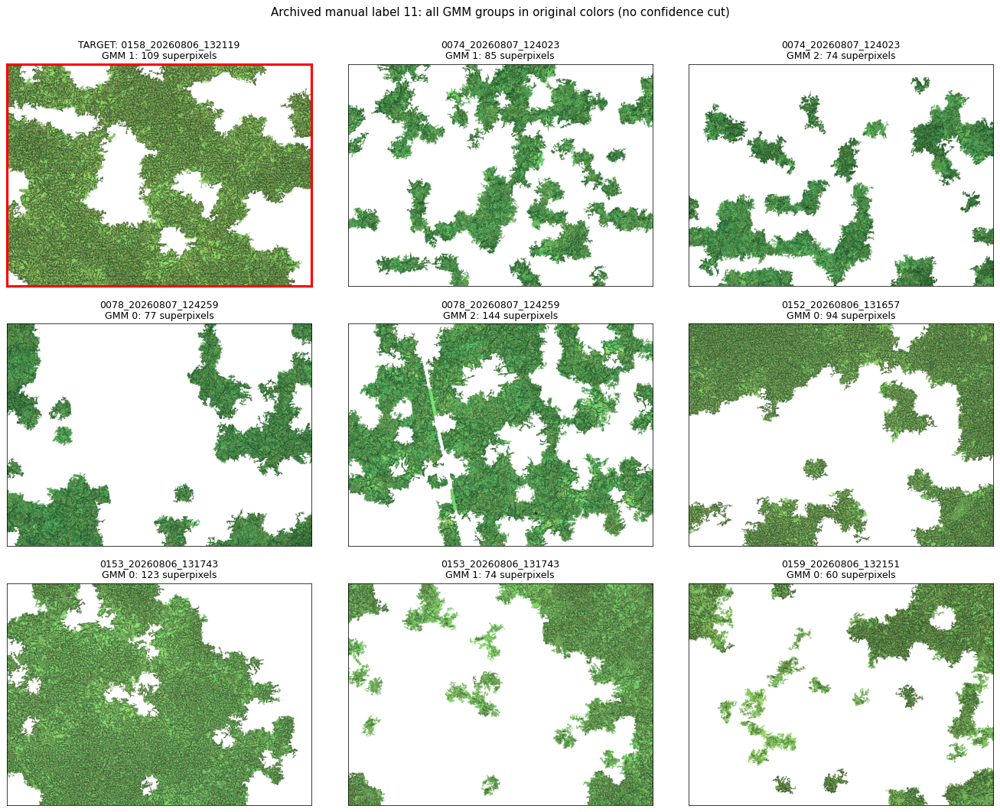

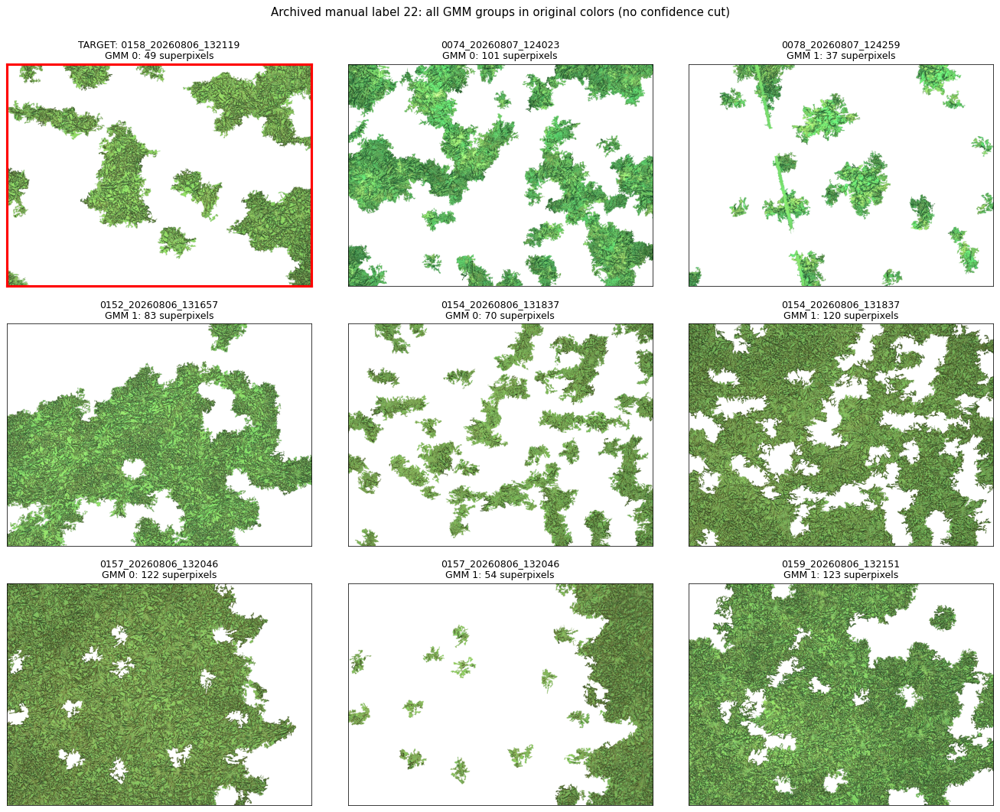

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")
for ax, (mode, column) in zip(axes[0], MODES.items()):
    ConfusionMatrixDisplay.from_predictions(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS,
                                           display_labels=[f"Label {c}" for c in CLASS_IDS], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{mode}: all out-of-fold predictions")
    pd.DataFrame(classification_report(cv_predictions.manual_label, cv_predictions[column], labels=CLASS_IDS,
                                      output_dict=True, zero_division=0)).T.to_csv(CV_DIR / f"report_{column}.csv")
for ax, metric in zip(axes[1], ["accuracy", "balanced_accuracy"]):
    for mode in MODES:
        rows = fold_metrics[fold_metrics["mode"] == mode]
        ax.plot(rows.fold, rows[metric], "o-", label=mode)
    ax.set(xlabel="Held-out fold", ylabel=metric.replace("_", " "), xticks=[1, 2, 3, 4], ylim=(0, 1.05))
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(CV_DIR / "05_cv_comparison.png", dpi=150)
plt.show()
plt.close(fig)
importance = pd.Series(np.mean(fold_importances, axis=0), index=FEATURE_NAMES).sort_values()
importance.rename("mean_importance").to_csv(CV_DIR / "feature_importance.csv")
fig, ax = plt.subplots(figsize=(8, 4))
importance.tail(8).plot.barh(ax=ax)
ax.set(xlabel="Mean impurity-based importance across four RFs", title="Eight highest feature importances")
fig.tight_layout()
fig.savefig(CV_DIR / "feature_importance.png", dpi=120)
plt.show()
plt.close(fig)
display(cv_summary)

from matplotlib.colors import ListedColormap

figure_dir = CV_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
vote_audit_rows = []
annotations = pd.read_csv(LABEL_PATH)
for image_id in sorted(cv_predictions.image_id.unique()):
    row = manifest[manifest.image_id == image_id].iloc[0]
    scored = cv_predictions[cv_predictions.image_id == image_id]
    fold = int(scored.fold.iloc[0])
    directory = OUTPUT_DIR / "rf_data" / f"image_{image_id:04d}"
    image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
    with np.load(CV_DIR / f"fold_{fold:02d}" / f"image_{image_id:04d}_predictions.npz") as saved:
        labels, direct, voted = saved["labels"], saved["rf_prediction"], saved["rf_gmm_prediction"]
    with np.load(directory / "gmm.npz") as saved: valid, groups = saved["valid_indices"], saved["cluster_labels"]
    for cluster in np.unique(groups):
        members = valid[groups == cluster]
        eligible = scored[scored.superpixel_index.isin(members)]
        manual_value = annotations.query("image_id == @image_id and gmm_cluster == @cluster").manual_label.iloc[0]
        manual_label = int(manual_value) if pd.notna(manual_value) else np.nan
        vote_audit_rows.append({"image_id": image_id, "name": row['name'], "fold": fold, "gmm_cluster": int(cluster),
                               "manual_label": manual_label, "n_total": len(members), "n_scored": len(eligible),
                               "n_unscored": len(members)-len(eligible), "votes_11_all": int(np.count_nonzero(direct[members] == 11)),
                               "votes_22_all": int(np.count_nonzero(direct[members] == 22)), "majority_label": int(voted[members[0]]),
                               "correct_rf_scored": int((eligible.manual_label == eligible.rf_prediction).sum()),
                               "correct_vote_scored": int((eligible.manual_label == eligible.rf_gmm_prediction).sum())})
    indices = np.searchsorted(labels, segments)
    true_labels = np.full(len(labels), -1, dtype=int)
    true_labels[scored.superpixel_index] = [CLASS_IDS.index(int(v)) for v in scored.manual_label]
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(image)
    axes[0, 0].set_title("Held-out original")
    axes[1, 0].imshow(true_labels[indices], cmap=ListedColormap(["lightgray", "tab:blue", "tab:orange"]), vmin=-1, vmax=1)
    axes[1, 0].set_title("Eligible labels: blue=11, orange=22, gray=unscored")
    for column_index, ((mode, column), full_prediction) in enumerate(zip(MODES.items(), [direct, voted]), 1):
        encoded = np.array([CLASS_IDS.index(int(v)) for v in full_prediction])
        axes[0, column_index].imshow(image)
        axes[0, column_index].imshow(encoded[indices], cmap=ListedColormap(["tab:blue", "tab:orange"]), vmin=0, vmax=1, alpha=.4)
        axes[0, column_index].set_title(mode)
        correct = np.full(len(labels), -1, dtype=int)
        correct[scored.superpixel_index] = (scored.manual_label == scored[column]).astype(int)
        axes[1, column_index].imshow(correct[indices], cmap=ListedColormap(["lightgray", "red", "green"]), vmin=-1, vmax=1)
        axes[1, column_index].set_title(f"Correctness: {(scored.manual_label == scored[column]).mean():.1%}")
    for ax in axes.flat: ax.axis("off")
    fig.suptitle(f"Fold {fold}: {row['name']}")
    fig.tight_layout()
    fig.savefig(figure_dir / f"held_out_{image_id:04d}.png", dpi=110)
    if image_id in {0, 1, 6}: plt.show()  # Include the requested low-accuracy case.
    plt.close(fig)
    del image, segments, indices
    gc.collect()
display(image_metrics)
vote_audit = pd.DataFrame(vote_audit_rows)
vote_audit.to_csv(CV_DIR / "gmm_vote_audit.csv", index=False)
print("Requested case: image 6, 0158_20260806_132119; counts use the same out-of-fold RF.")
display(vote_audit[vote_audit.image_id == 6])

# Visual inspection only: every archived label-11 GMM group, including unscored superpixels.
label11_groups = pd.read_csv(LABEL_PATH).query("manual_label == 11").copy()
label11_groups["is_target"] = (label11_groups.image_id == 6) & (label11_groups.gmm_cluster == 1)
label11_groups = label11_groups.sort_values(["is_target", "image_id", "gmm_cluster"], ascending=[False, True, True])
fig, axes = plt.subplots(int(np.ceil(len(label11_groups) / 3)), 3, figsize=(15, 4 * int(np.ceil(len(label11_groups) / 3))), squeeze=False)
panel_rows = []
for ax, row in zip(axes.flat, label11_groups.itertuples(index=False)):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
    with np.load(directory / "features.npz") as saved: labels = saved["labels"]
    with np.load(directory / "gmm.npz") as saved:
        members = saved["valid_indices"][saved["cluster_labels"] == row.gmm_cluster]
    mask = np.isin(segments, labels[members])
    view = np.full_like(image, 255)
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(("TARGET: " if row.is_target else "") + f"{row.name}\nGMM {row.gmm_cluster}: {len(members)} superpixels", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values(): spine.set(color="red" if row.is_target else "black", linewidth=2.5 if row.is_target else .6)
    panel_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": row.gmm_cluster,
                       "manual_label": 11, "n_superpixels": len(members), "is_target": row.is_target})
for ax in axes.flat[len(label11_groups):]: ax.axis("off")
fig.suptitle("Archived manual label 11: all GMM groups in original colors (no confidence cut)")
fig.tight_layout(rect=(0, 0, 1, .97), h_pad=3.0)
fig.savefig(CV_DIR / "label11_groups_comparison.png", dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(panel_rows).to_csv(CV_DIR / "label11_comparison_groups.csv", index=False)
del image, segments, mask, view

# Visual inspection only: every archived label-22 GMM group, including unscored superpixels.
label22_groups = pd.read_csv(LABEL_PATH).query("manual_label == 22").copy()
label22_groups["is_target"] = (label22_groups.image_id == 6) & (label22_groups.gmm_cluster == 0)
label22_groups = label22_groups.sort_values(["is_target", "image_id", "gmm_cluster"], ascending=[False, True, True])
fig, axes = plt.subplots(int(np.ceil(len(label22_groups) / 3)), 3, figsize=(15, 4 * int(np.ceil(len(label22_groups) / 3))), squeeze=False)
panel_rows = []
for ax, row in zip(axes.flat, label22_groups.itertuples(index=False)):
    directory = OUTPUT_DIR / "rf_data" / f"image_{row.image_id:04d}"
    image, segments = np.load(directory / "image.npy"), np.load(directory / "segments.npy")
    with np.load(directory / "features.npz") as saved: labels = saved["labels"]
    with np.load(directory / "gmm.npz") as saved:
        members = saved["valid_indices"][saved["cluster_labels"] == row.gmm_cluster]
    mask = np.isin(segments, labels[members])
    view = np.full_like(image, 255)
    view[mask] = image[mask]
    ax.imshow(view)
    ax.set_title(("TARGET: " if row.is_target else "") + f"{row.name}\nGMM {row.gmm_cluster}: {len(members)} superpixels", fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values(): spine.set(color="red" if row.is_target else "black", linewidth=2.5 if row.is_target else .6)
    panel_rows.append({"image_id": row.image_id, "name": row.name, "gmm_cluster": row.gmm_cluster,
                       "manual_label": 22, "n_superpixels": len(members), "is_target": row.is_target})
for ax in axes.flat[len(label22_groups):]: ax.axis("off")
fig.suptitle("Archived manual label 22: all GMM groups in original colors (no confidence cut)")
fig.tight_layout(rect=(0, 0, 1, .97), h_pad=3.0)
fig.savefig(CV_DIR / "label22_groups_comparison.png", dpi=150)
plt.show()
plt.close(fig)
pd.DataFrame(panel_rows).to_csv(CV_DIR / "label22_comparison_groups.csv", index=False)
del image, segments, mask, view